# Draw a FaceRhythm ROI (any camera: set `CAM`)

For the O2 FaceRhythm run (`scripts/o2_face_rhythm.py`). Run in the **`fr`** env (JupyterLab started from it, or VS Code with the `fr` kernel).

Writes `<dlc>/face_rhythm/cam4/rois/<animal>_<date>/ROIs.h5`, the file the O2 runner reads. Use it for:
* the **pilot**: draw directly on one session (default PS94 0810), and
* the **master ROI**: set `SESSION` to the master template's session; registration then warps its points to every session.

**Two polygons:**
1. **face**: where the tracking points go (a grid every `POINT_SPACING` px).
2. **mask**: what the tracker may see; pixels outside it are blacked out. Draw it **~25 px outside the face** on the top and sides (each point is tracked from a 40 x 40 px window). At the **bottom** keep it just **above the highest spout tips** (orange) so the rod stays out. Points are seeded only where face and mask overlap.

**Drawing** (matplotlib `PolygonSelector`): **click** each vertex; **click the first vertex** to close. Then **drag** a vertex to move it, **shift-drag** to move the whole polygon, **Esc** to start over. Zoom / pan with the toolbar, and **switch the zoom/pan button off again** before clicking vertices. `FIGSIZE` sets the figure size.

**Editing** an existing ROI: set `EDIT = True`; the saved polygons open ready to drag. The previous `ROIs.h5` is kept as `ROIs_<time>.h5` when you save.

**Master ROI (PS93_20260821).** Opens from the registered draft (`EDIT = True`). The small dots are every session's LP landmarks mapped into master coordinates: **orange = close-spout tips, gold = far-spout tips, cyan = nose, green = jaw at rest**. The **face** polygon should reach up to the eyes; the **mask's bottom edge** goes just above the highest **orange** (close-spout) dots. After saving, the pose/3-D window warps the master points and polygons to every registered session (`scripts/face_rhythm_warp_rois.py to-sessions`).

**Other cameras (`CAM` = cam1 / cam2 / cam3, 10-22).** Same two polygons on that camera's master (`<dlc>/face_rhythm/<CAM>/register/templates.json`), then `python scripts/face_rhythm_warp_rois.py to-sessions --cam <CAM>`. No LP landmarks there (no nose / jaw / spout marks). **Side views (cam2, cam3):** the face polygon is the HEAD only; keep the mask off the body, forepaws and treadmill (they move with running and grooming, not the face), and off the spout's path in front of the mouth. **cam1 (from below):** the centre spout rod hangs through the middle of the face -- keep the face polygon above the rod's tip region or accept masking it post hoc.

In [1]:
%matplotlib widget
import numpy as np, face_rhythm as fr
import matplotlib.pyplot as plt
from matplotlib.widgets import PolygonSelector
from pathlib import Path

CAM = "cam4"                       # cam4 | cam1 | cam2 | cam3 (wfield_local/face_rhythm_cams.py)
SESSION = "PS95_20260812"          # <animal>_<YYYYMMDD>; PS93_20260821 = the cohort MASTER (register/templates.json)
POINT_SPACING = 9                  # px; 9 -> ~1500-2000 points on a cam4 face
FIGSIZE = 11                       # inches
EDIT = True                        # True: start from the saved ROIs.h5 polygons (master: the registered draft)
DLC = Path(r"M:\MICROSCOPE\Priya\DeepLabCut\Widefield")
OUT = DLC / "face_rhythm" / CAM / "rois" / SESSION / "ROIs.h5"

Z = np.load(DLC / "face_rhythm" / CAM / "frames" / f"{SESSION}.npz")
img = Z["median"].astype(np.float32) / 255.0      # median rest face (scripts/face_rhythm_prep.py frames)
START = {}
if EDIT and OUT.exists():
    old = fr.rois.ROIs(select_mode="file", path_file=str(OUT), verbose=0)
    START = dict(zip(["face", "mask"], [np.asarray(v) for v in old.roi_points.values()]))
# every session's LP landmarks mapped into master coordinates (registration; only meaningful on the master face)
_OVF = DLC / "face_rhythm" / CAM / "register" / "master_overlay.npz"      # cam4 only (LP landmarks)
OV = np.load(_OVF) if _OVF.exists() and SESSION == str(np.load(_OVF)["master"]) else None

def overlay(ax, ms=2):
    """All sessions' spout tips (close = solid colours, far = paler) + nose / jaw at rest, in master px."""
    if OV is None:
        return
    for j, pos in enumerate(OV["positions"]):
        ax.plot(*OV["tip_xy"][:, j].T, ".", ms=ms, alpha=.5, label=str(pos),
                color=("tab:orange" if "close" in str(pos) else "gold"))
    ax.plot(*OV["nose_xy"].T, ".", ms=ms, alpha=.4, color="c")
    ax.plot(*OV["jaw_xy"].T, ".", ms=ms, alpha=.4, color="lime")

print(img.shape, "nose", Z["nose"], "jaw", Z["jaw"], "| editing" if START else "")

C:\Users\SabatiniLab\miniconda3\envs\fr\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


(680, 680) nose [341.98947 267.93704] jaw [357.24008 416.0074 ] | editing


In [2]:
POLY, _SEL = dict(START), {}

def draw(name):
    """Open the face with a polygon tool for `name` ("face" / "mask"); the other polygon is shown for reference."""
    fig, ax = plt.subplots(figsize=(FIGSIZE, FIGSIZE))
    ax.imshow(img, cmap="gray")
    for k, v in POLY.items():
        if k != name:
            ax.plot(*np.vstack([v, v[:1]]).T, "-", lw=1, color="yellow" if k == "face" else "red")
    for xy in Z["tip_xy"]:
        ax.plot(*xy, "o", ms=5, color="tab:orange")
    overlay(ax)
    ax.plot(*Z["nose"], "+", color="c", ms=12); ax.plot(*Z["jaw"], "+", color="lime", ms=12)
    PAD = 60                                          # px of border, so off-image vertices stay grabbable
    ax.set_xlim(-PAD, img.shape[1] + PAD); ax.set_ylim(img.shape[0] + PAD, -PAD)
    ax.add_patch(plt.Rectangle((-0.5, -0.5), img.shape[1], img.shape[0], fill=False, ec="w", lw=0.8, ls="--"))
    ax.set_title(f"{SESSION}: draw '{name}' (click vertices, click the first to close; drag to adjust)")
    s = PolygonSelector(ax, lambda v: POLY.__setitem__(name, np.asarray(v, np.float32)), grab_range=10,
                        props=dict(color="yellow" if name == "face" else "red", linewidth=1.5))
    if name in POLY:
        s.verts = [tuple(p) for p in POLY[name]]
    _SEL[name] = s                                    # keep a reference, or the tool stops responding
    fig.tight_layout()
    plt.show()

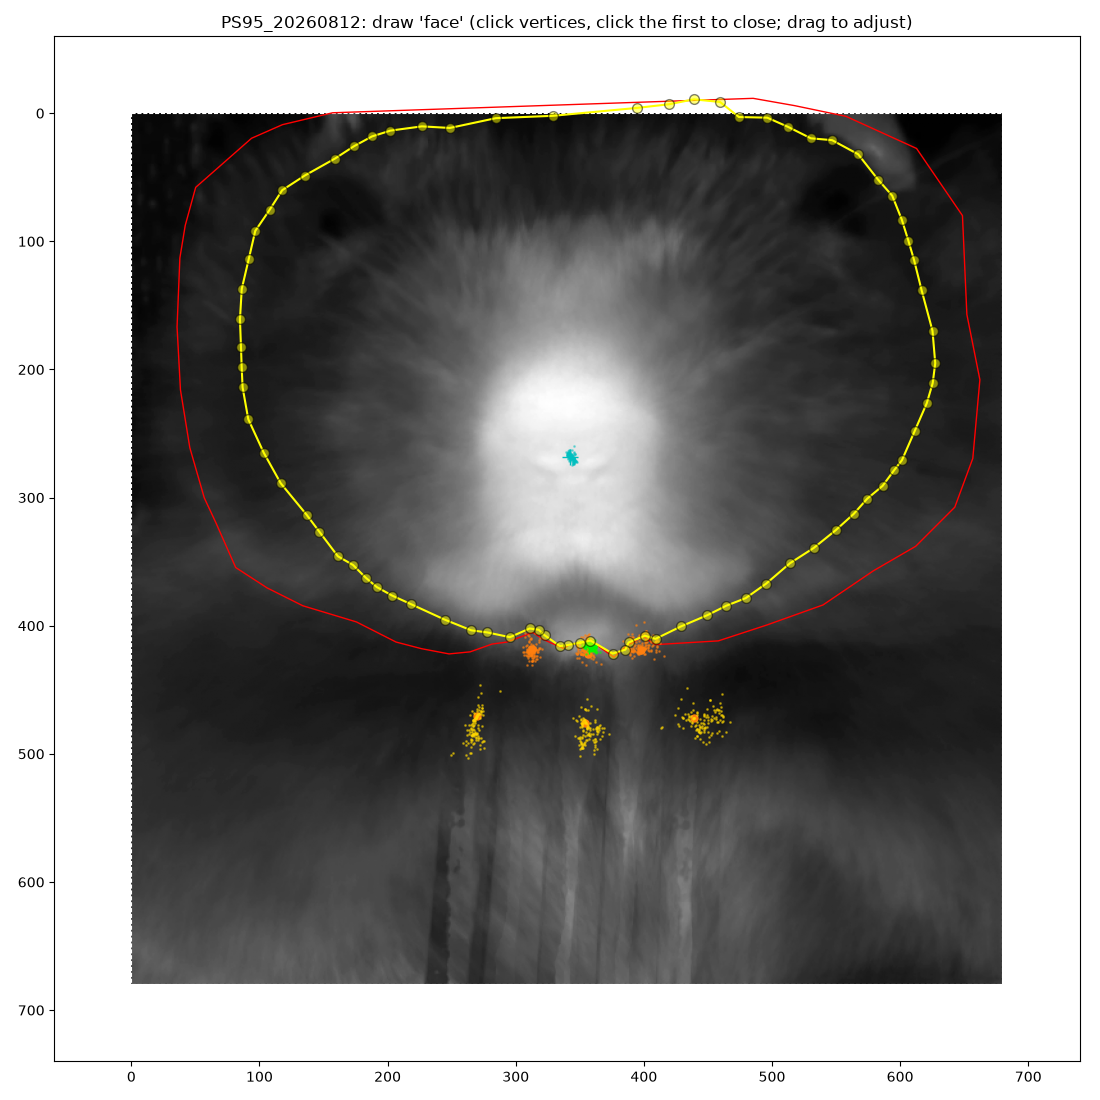

In [3]:
draw("face")

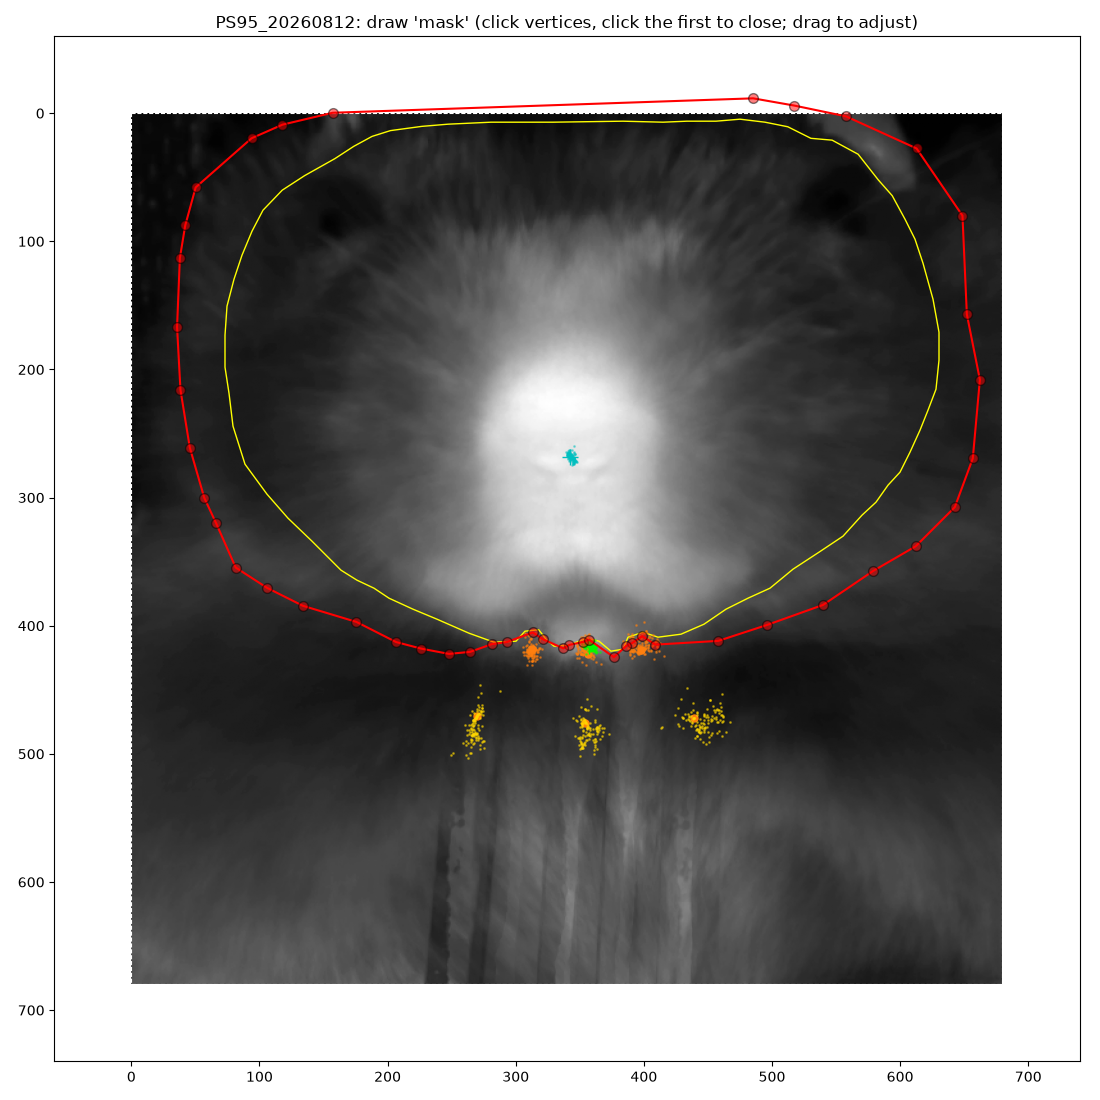

In [5]:
draw("mask")

2287 points


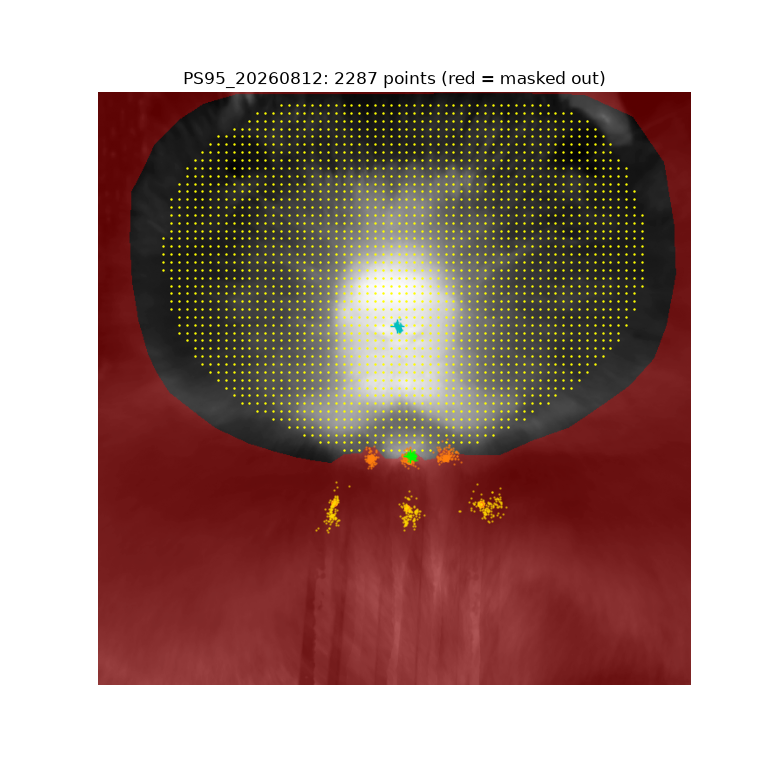

In [6]:
# build the ROIs from the two polygons, seed points where BOTH cover, and check
assert {"face", "mask"} <= set(POLY), f"draw both polygons first (have {list(POLY)})"
rois = fr.rois.ROIs(select_mode="custom", exampleImage=img,
                    coords_rois={"face": POLY["face"], "mask": POLY["mask"]}, verbose=1)
rois.make_points(rois=[rois[0], rois[1]], point_spacing=POINT_SPACING)
P = rois.point_positions
print(len(P), "points")

over = np.zeros(img.shape + (4,)); over[~rois[1]] = [1, 0, 0, 0.35]       # red = blacked out for tracking
fig, ax = plt.subplots(figsize=(FIGSIZE * 0.7, FIGSIZE * 0.7))
ax.imshow(img, cmap="gray"); ax.imshow(over)
ax.plot(*P.T, ".", ms=1.5, color="yellow")
for xy in Z["tip_xy"]:
    ax.plot(*xy, "o", ms=4, color="tab:orange")
overlay(ax, ms=1.5)
ax.plot(*Z["nose"], "+", color="c", ms=10); ax.plot(*Z["jaw"], "+", color="lime", ms=10)
ax.set_xlim(-0.5, img.shape[1] - 0.5); ax.set_ylim(img.shape[0] - 0.5, -0.5)   # image bounds (polygons may run past)
ax.set_title(f"{SESSION}: {len(P)} points (red = masked out)"); ax.axis("off")
plt.show()

In [7]:
# save in the format the O2 runner reads; an earlier version is moved aside (ROIs_<time>.h5), not deleted
import time
assert "MICROSCOPE" in str(OUT) and "Priya" in str(OUT)
OUT.parent.mkdir(parents=True, exist_ok=True)
if OUT.exists():
    old = OUT.with_name(f"ROIs_{time.strftime('%Y%m%d_%H%M%S', time.localtime(OUT.stat().st_mtime))}.h5")
    OUT.rename(old); print("previous version ->", old.name)
fr.h5_handling.simple_save({"mask_images": rois.mask_images, "roi_points": rois.roi_points,
                            "exampleImage": img, "point_positions": P}, str(OUT))
chk = fr.rois.ROIs(select_mode="file", path_file=str(OUT), verbose=0)
print("saved", OUT, len(chk.point_positions), "points,", len(chk), "masks")

previous version -> ROIs_20261021_101511.h5
saved M:\MICROSCOPE\Priya\DeepLabCut\Widefield\face_rhythm\cam4\rois\PS95_20260812\ROIs.h5 2287 points, 2 masks
